## Partindo do que já ficou pronto na Etapa 1 (EDA+Baseline)

Recarregar os dados e repitir o pré-processamento já validado: correção do
TotalCharges, remoção de customerID, encoding das categóricas e split
treino/teste estratificado

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

from pipeline import construir_pipeline

df = pd.read_csv('../data/Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

df_model = df.drop(columns=['customerID'])
df_model['Churn'] = df_model['Churn'].map({'Yes': 1, 'No': 0})

X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1109)

## Baseline: Regressão Logística (recapitulando da Etapa 1)

Reproduzir o baseline da Etapa 1, com os dados escalados e
class_weight='balanced', para servir de referência direta na comparação
com os modelos de árvore e rede neural deste notebook.

In [2]:
from sklearn.linear_model import LogisticRegression

lr_model = construir_pipeline(LogisticRegression(max_iter=1000, random_state=1109, class_weight='balanced'))
lr_model.fit(X_train, y_train)

print(classification_report(y_test, lr_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



## Random Forest

Testar um modelo baseado em árvores pra comparar com o baseline linear.
Random Forest costuma lidar melhor com relações não-lineares, e não
precisa dos dados escalados como a regressão logística precisava.

In [3]:
from sklearn.ensemble import RandomForestClassifier

rf_model = construir_pipeline(RandomForestClassifier(class_weight='balanced', random_state=1109))
rf_model.fit(X_train, y_train)

print(classification_report(y_test, rf_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.56      0.64      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.78      1409



## Árvore de Decisão (*Decision Tree* / CART)

Testar uma árvore de decisão simples, tende a
ser menos conservadora com a classe minoritária que um *ensemble*.

In [4]:
from sklearn.tree import DecisionTreeClassifier

dt_model = construir_pipeline(DecisionTreeClassifier(class_weight='balanced', random_state=1109))
dt_model.fit(X_train, y_train)

print(classification_report(y_test, dt_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.83      0.80      0.81      1035
           1       0.50      0.54      0.52       374

    accuracy                           0.73      1409
   macro avg       0.66      0.67      0.67      1409
weighted avg       0.74      0.73      0.74      1409



## MLPClassifier (rede neural simples)

Testar uma rede neural simples do scikit-learn. 

In [5]:
from sklearn.neural_network import MLPClassifier

mlp_model = construir_pipeline(MLPClassifier(random_state=1109, max_iter=500))
mlp_model.fit(X_train, y_train)

print(classification_report(y_test, mlp_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.83      0.88      0.85      1035
           1       0.60      0.50      0.54       374

    accuracy                           0.78      1409
   macro avg       0.71      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409



## Ajuste do MLP: mais iterações + balanceamento manual

MLPClassifier não tem class_weight, mas aceita sample_weight no fit,
calculando pesos balanceados manualmente com compute_sample_weight, igual
em espírito ao que fizemos nos outros modelos. Também aumento max_iter
para resolver o warning de convergência.

In [6]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

mlp_model = construir_pipeline(MLPClassifier(random_state=1109, max_iter=1000))
mlp_model.fit(X_train, y_train, modelo__sample_weight=sample_weights)

print(classification_report(y_test, mlp_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.87      0.75      0.80      1035
           1       0.50      0.69      0.58       374

    accuracy                           0.73      1409
   macro avg       0.68      0.72      0.69      1409
weighted avg       0.77      0.73      0.74      1409



## MLP com balanceamento (SMOTE)

Sem balanceamento, o MLP ficou com recall baixo (0,50), parecido com o
problema que tivemos no baseline original. Com sample_weight subiu para
0,69. Testar agora uma alternativa: oversampling com SMOTE.

In [7]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

base = construir_pipeline(MLPClassifier(random_state=1109, max_iter=1000))
mlp_model = ImbPipeline([
    ('pre', base.named_steps['pre']),
    ('smote', SMOTE(random_state=1109)),
    ('modelo', base.named_steps['modelo']),
])
mlp_model.fit(X_train, y_train)

print(classification_report(y_test, mlp_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.84      0.82      0.83      1035
           1       0.53      0.57      0.55       374

    accuracy                           0.75      1409
   macro avg       0.68      0.69      0.69      1409
weighted avg       0.76      0.75      0.75      1409



## Validação cruzada de todos os modelos

Comparar os modelos por um único split treino/teste pode premiar a sorte de uma divisão específica, e usar o
conjunto de teste para **escolher** o modelo faz com que ele deixe de ser uma estimativa honesta do desempenho final.

Por isso, todos os modelos são avaliados com a **mesma** validação cruzada estratificada (5 folds, mesma seed),
usando **apenas o conjunto de treino**. O conjunto de teste fica reservado para a avaliação final do campeão.

Além das métricas no limiar 0,5 (recall, precision, F1), medimos duas métricas **independentes de limiar**:
- **ROC-AUC**: capacidade de ordenar churners acima de não-churners;
- **PR-AUC (Average Precision)**: mais informativa que a ROC em dados desbalanceados, pois foca na classe positiva.

Isso é importante porque cada modelo foi balanceado de um jeito diferente (`class_weight`, `sample_weight`, SMOTE ou
nenhum), o que desloca suas probabilidades: comparar só o recall em 0,5 mistura a qualidade do modelo com a escolha do limiar.

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1109)
metricas = ['recall', 'precision', 'f1', 'roc_auc', 'average_precision']


def mlp_smote():
    base = construir_pipeline(MLPClassifier(random_state=1109, max_iter=1000))
    return ImbPipeline([
        ('pre', base.named_steps['pre']),
        ('smote', SMOTE(random_state=1109)),
        ('modelo', base.named_steps['modelo']),
    ])


# (nome, pipeline, parâmetros extras do fit)
candidatos = [
    ('Regressão Logística (balanced)', construir_pipeline(LogisticRegression(max_iter=1000, random_state=1109, class_weight='balanced')), None),
    ('Regressão Logística (sem balanceamento)', construir_pipeline(LogisticRegression(max_iter=1000, random_state=1109)), None),
    ('Random Forest (balanced)', construir_pipeline(RandomForestClassifier(class_weight='balanced', random_state=1109)), None),
    ('Árvore de Decisão (balanced)', construir_pipeline(DecisionTreeClassifier(class_weight='balanced', random_state=1109)), None),
    ('MLP (sem balanceamento)', construir_pipeline(MLPClassifier(random_state=1109, max_iter=1000)), None),
    ('MLP (sample_weight balanced)', construir_pipeline(MLPClassifier(random_state=1109, max_iter=1000)),
     {'modelo__sample_weight': compute_sample_weight(class_weight='balanced', y=y_train)}),
    ('MLP (SMOTE)', mlp_smote(), None),
]

resultados_cv = {}
for nome, modelo, params in candidatos:
    # sample_weight é fatiado automaticamente para cada fold
    r = cross_validate(modelo, X_train, y_train, cv=skf, scoring=metricas, params=params, n_jobs=-1)
    resultados_cv[nome] = {m: r[f'test_{m}'] for m in metricas}

linhas = []
for nome, scores in resultados_cv.items():
    linha = {'modelo': nome}
    for m in metricas:
        linha[f'{m}_media'] = scores[m].mean()
        linha[f'{m}_desvio'] = scores[m].std()
    linhas.append(linha)

tabela_cv = pd.DataFrame(linhas).set_index('modelo').sort_values('recall_media', ascending=False)
tabela_cv.to_csv('../models/cv_results.csv')  # registro do experimento

pd.DataFrame({
    m: tabela_cv[f'{m}_media'].map('{:.3f}'.format) + ' ± ' + tabela_cv[f'{m}_desvio'].map('{:.3f}'.format)
    for m in metricas
})

,recall,precision,f1,roc_auc,average_precision
modelo,,,,,
Regressão Logística (balanced),0.805 ± 0.027,0.515 ± 0.026,0.628 ± 0.020,0.845 ± 0.013,0.651 ± 0.017
MLP (sample_weight balanced),0.644 ± 0.041,0.510 ± 0.015,0.568 ± 0.011,0.794 ± 0.012,0.543 ± 0.012
Random Forest (balanced),0.637 ± 0.012,0.568 ± 0.021,0.600 ± 0.011,0.826 ± 0.009,0.618 ± 0.023
MLP (SMOTE),0.599 ± 0.019,0.507 ± 0.017,0.549 ± 0.011,0.779 ± 0.009,0.524 ± 0.010
Regressão Logística (sem balanceamento),0.547 ± 0.022,0.640 ± 0.027,0.590 ± 0.018,0.845 ± 0.013,0.654 ± 0.016
MLP (sem balanceamento),0.512 ± 0.045,0.581 ± 0.034,0.542 ± 0.026,0.797 ± 0.013,0.563 ± 0.028
Árvore de Decisão (balanced),0.492 ± 0.013,0.506 ± 0.031,0.498 ± 0.013,0.658 ± 0.010,0.383 ± 0.014


### O campeão é melhor de verdade ou foi ruído?

Como todos os modelos foram avaliados nos **mesmos folds**, podemos comparar fold a fold (comparação pareada).
Se a Regressão Logística vence o concorrente em todos os 5 folds e a diferença média é maior que o desvio,
a vantagem não é fruto de um split favorável.

In [9]:
campeao = 'Regressão Logística (balanced)'

comparacao = []
for nome in resultados_cv:
    if nome == campeao:
        continue
    for m in ['recall', 'roc_auc', 'average_precision']:
        dif = resultados_cv[campeao][m] - resultados_cv[nome][m]
        comparacao.append({
            'concorrente': nome,
            'métrica': m,
            'diferença média': round(dif.mean(), 3),
            'desvio da diferença': round(dif.std(), 3),
            'folds em que a LR vence': f'{(dif > 0).sum()}/5',
        })

pd.DataFrame(comparacao).pivot(index='concorrente', columns='métrica', values='folds em que a LR vence')

métrica,average_precision,recall,roc_auc
concorrente,,,
MLP (SMOTE),5/5,5/5,5/5
MLP (sample_weight balanced),5/5,5/5,5/5
MLP (sem balanceamento),5/5,5/5,5/5
Random Forest (balanced),4/5,5/5,5/5
Regressão Logística (sem balanceamento),0/5,5/5,1/5
Árvore de Decisão (balanced),5/5,5/5,5/5


## Avaliação final no conjunto de teste: curvas ROC e Precisão-Revocação

Só depois da escolha feita pela validação cruzada usamos o conjunto de teste. As curvas mostram o desempenho de cada modelo
em **todos os limiares**, e o ponto marcado é o limiar 0,5 usado pela API.

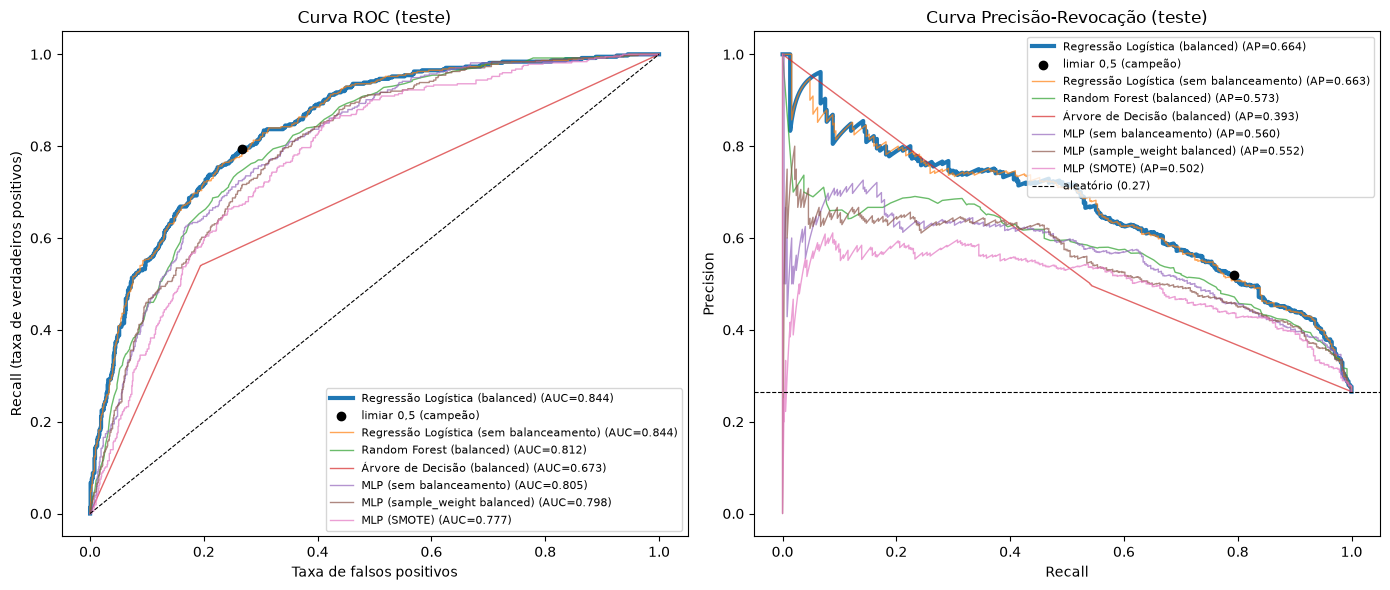

,roc_auc_teste,pr_auc_teste
modelo,,
Regressão Logística (balanced),0.844,0.664
Regressão Logística (sem balanceamento),0.844,0.663
Random Forest (balanced),0.812,0.573
Árvore de Decisão (balanced),0.673,0.393
MLP (sem balanceamento),0.805,0.560
MLP (sample_weight balanced),0.798,0.552
MLP (SMOTE),0.777,0.502


In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve

from pipeline import LIMIAR_CHURN

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 6))
metricas_teste = []

for nome, modelo, params in candidatos:
    modelo.fit(X_train, y_train, **(params or {}))
    prob = modelo.predict_proba(X_test)[:, 1]
    auc, ap = roc_auc_score(y_test, prob), average_precision_score(y_test, prob)
    metricas_teste.append({'modelo': nome, 'roc_auc_teste': round(auc, 3), 'pr_auc_teste': round(ap, 3)})

    destaque = dict(linewidth=3) if nome == campeao else dict(linewidth=1, alpha=0.7)
    fpr, tpr, _ = roc_curve(y_test, prob)
    linha, = ax_roc.plot(fpr, tpr, label=f'{nome} (AUC={auc:.3f})', **destaque)
    precisao, revocacao, _ = precision_recall_curve(y_test, prob)
    ax_pr.plot(revocacao, precisao, label=f'{nome} (AP={ap:.3f})', color=linha.get_color(), **destaque)

    if nome == campeao:
        pred = prob >= LIMIAR_CHURN
        tp = (pred & (y_test == 1)).sum()
        ax_roc.scatter(pred[y_test == 0].mean(), tp / (y_test == 1).sum(), color='black', zorder=5, label='limiar 0,5 (campeão)')
        ax_pr.scatter(tp / (y_test == 1).sum(), tp / pred.sum(), color='black', zorder=5, label='limiar 0,5 (campeão)')

ax_roc.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
ax_roc.set(title='Curva ROC (teste)', xlabel='Taxa de falsos positivos', ylabel='Recall (taxa de verdadeiros positivos)')
ax_pr.axhline(y_test.mean(), color='k', linestyle='--', linewidth=0.8, label=f'aleatório ({y_test.mean():.2f})')
ax_pr.set(title='Curva Precisão-Revocação (teste)', xlabel='Recall', ylabel='Precision')
ax_roc.legend(fontsize=8, loc='lower right')
ax_pr.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

pd.DataFrame(metricas_teste).set_index('modelo')

## Conclusão da Etapa 2 e Tabela Comparativa de modelos

**Validação cruzada (5 folds estratificados, só no treino): média ± desvio**

| Modelo | Recall | Precision | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|
| **Regressão Logística (balanced)** | **0,805 ± 0,027** | 0,515 ± 0,026 | **0,628 ± 0,020** | **0,845 ± 0,013** | 0,651 ± 0,017 |
| Regressão Logística (sem balanceamento) | 0,547 ± 0,022 | 0,640 ± 0,027 | 0,590 ± 0,018 | **0,845 ± 0,013** | **0,654 ± 0,016** |
| Random Forest (balanced) | 0,637 ± 0,012 | 0,568 ± 0,021 | 0,600 ± 0,011 | 0,826 ± 0,009 | 0,618 ± 0,023 |
| Árvore de Decisão (balanced) | 0,492 ± 0,013 | 0,506 ± 0,031 | 0,498 ± 0,013 | 0,658 ± 0,010 | 0,383 ± 0,014 |
| MLP (sem balanceamento) | 0,512 ± 0,045 | 0,581 ± 0,034 | 0,542 ± 0,026 | 0,797 ± 0,013 | 0,563 ± 0,028 |
| MLP (sample_weight balanced) | 0,644 ± 0,041 | 0,510 ± 0,015 | 0,568 ± 0,011 | 0,794 ± 0,012 | 0,543 ± 0,012 |
| MLP (SMOTE) | 0,599 ± 0,019 | 0,507 ± 0,017 | 0,549 ± 0,011 | 0,779 ± 0,009 | 0,524 ± 0,010 |

Os resultados por modelo também ficam gravados em `models/cv_results.csv`.

**Conjunto de teste (avaliação final, 1.409 clientes)**

| Modelo | ROC-AUC | PR-AUC |
|---|---|---|
| **Regressão Logística (balanced)** | **0,844** | **0,664** |
| Regressão Logística (sem balanceamento) | 0,844 | 0,663 |
| Random Forest (balanced) | 0,812 | 0,573 |
| MLP (sem balanceamento) | 0,805 | 0,560 |
| MLP (sample_weight balanced) | 0,798 | 0,552 |
| MLP (SMOTE) | 0,777 | 0,502 |
| Árvore de Decisão (balanced) | 0,673 | 0,393 |

**Leitura dos resultados:**

- A Regressão Logística balanceada vence **todos** os modelos de árvore e de rede neural em **todos os 5 folds**,
  tanto em recall quanto em ROC-AUC e PR-AUC. A vantagem não depende do limiar nem de um split favorável.
- As métricas independentes de limiar (ROC-AUC e PR-AUC) mostram que a vantagem não é só efeito do balanceamento:
  a regressão logística **ordena** melhor os clientes por risco do que Random Forest e MLP.
- As duas versões da Regressão Logística têm praticamente o mesmo ROC-AUC/PR-AUC: o `class_weight='balanced'` não
  muda a capacidade de ordenar os clientes, ele **desloca o ponto de operação** para um recall maior (0,80 vs. 0,55),
  que é o que o ML Canvas pede (falso negativo custa mais caro).
- Modelos mais complexos (árvore, ensemble, rede neural) não superaram o modelo linear, o que é plausível porque a EDA
  já mostrava relações bem diretas de `Contract` e `tenure` com o churn. Mesmo que a diferença fosse marginal, a regra
  do 1 desvio-padrão (Aula 07) recomendaria o modelo mais simples e interpretável.
- Ressalva: Random Forest e MLP foram avaliados com os hiperparâmetros padrão; um ajuste de hiperparâmetros poderia
  reduzir a distância, mas dificilmente inverteria uma diferença de ~0,03 a 0,05 em ROC-AUC.

**Modelo campeão: Regressão Logística com class_weight='balanced'**
(recall médio de 0,805 ± 0,027 na validação cruzada e 0,79 no conjunto de teste)

In [11]:
import joblib

joblib.dump(lr_model, '../models/churn_pipeline.pkl')

['../models/churn_pipeline.pkl']

In [12]:
loaded_model = joblib.load('../models/churn_pipeline.pkl')

print(loaded_model)
print(loaded_model.named_steps['modelo'].coef_)  # os pesos que o modelo aprendeu pra cada variável
print(loaded_model.named_steps['pre'].named_transformers_['num'].mean_)  # a média que o scaler guardou de cada variável numérica

Pipeline(steps=[('pre',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('num', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'T